In [1]:
# M1 — Crop & Fertilizer Recommender

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/M1_crop_fertilizer', exist_ok=True)
SAVE_DIR = '/content/drive/MyDrive/M1_crop_fertilizer'

Mounted at /content/drive


In [3]:
# %% [1] SETUP
# !pip install -q tensorflow scikit-learn shap gradio pandas numpy matplotlib kagglehub

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
import tensorflow as tf
from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

In [4]:
# %% [2] LOAD DATASETS
# Dataset 1: "Crop Recommendation Dataset" (atharvaingle/crop-recommendation-dataset)
#   columns: N, P, K, temperature, humidity, ph, rainfall, label
# Dataset 2: "Fertilizer Prediction" (gdabhishek/fertilizer-prediction)
#   columns: Temparature, Humidity, Moisture, Soil Type, Crop Type,
#            Nitrogen, Potassium, Phosphorous, Fertilizer Name

import kagglehub
crop_path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")
fert_path = kagglehub.dataset_download("gdabhishek/fertilizer-prediction")

crop_df = pd.read_csv(f"{crop_path}/Crop_recommendation.csv")
fert_df = pd.read_csv(f"{fert_path}/Fertilizer Prediction.csv")

print(crop_df.shape, fert_df.shape)
print(crop_df.columns.tolist())
print(fert_df.columns.tolist())

100%|██████████| 63.7k/63.7k [00:00<00:00, 54.6MB/s]

Extracting files...


100%|██████████| 1.27k/1.27k [00:00<00:00, 1.46MB/s]

Extracting files...
(2200, 8) (99, 9)
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
['Temparature', 'Humidity ', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'Fertilizer Name']


In [5]:
# %% [3] CLEAN
crop_df = crop_df.dropna().drop_duplicates()
fert_df = fert_df.dropna().drop_duplicates()

# standardize column names
fert_df = fert_df.rename(columns={
    "Temparature": "temperature",
    "Humidity ": "humidity",
    "Soil Type": "soil_type",
    "Crop Type": "label",
    "Nitrogen": "N",
    "Potassium": "K",
    "Phosphorous": "P",
    "Fertilizer Name": "fertilizer",
})
crop_df = crop_df.rename(columns={"label": "label"})

In [6]:
# %% [4] ALIGN VOCABULARY
# Crop names differ in case/spacing between the two sources — normalize both.
def normalize_name(s):
    return str(s).strip().lower().replace(" ", "")

crop_df["label"] = crop_df["label"].apply(normalize_name)
fert_df["label"] = fert_df["label"].apply(normalize_name)

# known synonyms between the two datasets — same crop, different names
crop_synonyms = {
    "paddy": "rice",
}
fert_df["label"] = fert_df["label"].replace(crop_synonyms)

crop_vocab = set(crop_df["label"].unique())
fert_vocab = set(fert_df["label"].unique())
shared = crop_vocab & fert_vocab
print(f"Crop-only vocab: {len(crop_vocab)}, Fertilizer-only vocab: {len(fert_vocab)}, Shared: {len(shared)}")
print("Fertilizer dataset crops NOT in crop dataset:", sorted(fert_vocab - crop_vocab))
print(f"{len(shared)} of {len(fert_vocab)} fertilizer-dataset crops are usable")
print("In fertilizer but not crop dataset:", fert_vocab - crop_vocab)
print("In crop but not fertilizer dataset:", crop_vocab - fert_vocab)
# NOTE: inspect the printed diffs and add manual remaps above if names still mismatch, e.g.:
# crop_synonyms["mothbeans"] = "moth_beans"; fert_df["label"] = fert_df["label"].replace(crop_synonyms)

Crop-only vocab: 22, Fertilizer-only vocab: 11, Shared: 3
Fertilizer dataset crops NOT in crop dataset: ['barley', 'groundnuts', 'millets', 'oilseeds', 'pulses', 'sugarcane', 'tobacco', 'wheat']
3 of 11 fertilizer-dataset crops are usable
In fertilizer but not crop dataset: {'tobacco', 'sugarcane', 'groundnuts', 'wheat', 'barley', 'pulses', 'millets', 'oilseeds'}
In crop but not fertilizer dataset: {'papaya', 'coconut', 'apple', 'banana', 'pomegranate', 'coffee', 'mungbean', 'grapes', 'mango', 'lentil', 'blackgram', 'orange', 'jute', 'mothbeans', 'kidneybeans', 'chickpea', 'pigeonpeas', 'muskmelon', 'watermelon'}


In [7]:
print("Fertilizer dataset crops NOT in crop dataset:", sorted(fert_vocab - crop_vocab))

Fertilizer dataset crops NOT in crop dataset: ['barley', 'groundnuts', 'millets', 'oilseeds', 'pulses', 'sugarcane', 'tobacco', 'wheat']


In [8]:
# %% [5] ENCODE CATEGORICALS
crop_encoder = LabelEncoder().fit(sorted(crop_vocab))                          # stage 1 output (22 crop-dataset classes)
fert_crop_encoder = LabelEncoder().fit(sorted(fert_df["label"].unique()))      # stage 2's own crop vocabulary (separate from crop_encoder)
soil_encoder = LabelEncoder().fit(sorted(fert_df["soil_type"].unique()))
fert_encoder = LabelEncoder().fit(sorted(fert_df["fertilizer"].unique()))

crop_df["crop_id"] = crop_encoder.transform(crop_df["label"])

In [9]:
# %% [6] SCALE NUMERIC FEATURES + STRATIFIED SPLIT — STAGE 1 (crop model)
NUM_COLS_CROP = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

X_num = crop_df[NUM_COLS_CROP].values
y_crop = crop_df["crop_id"].values

scaler_crop = StandardScaler().fit(X_num)
X_num_scaled = scaler_crop.transform(X_num)

X_train, X_test, y_train, y_test = train_test_split(
    X_num_scaled, y_crop, test_size=0.2, stratify=y_crop, random_state=42
)


In [10]:
# %% [7] STAGE 1 MODEL — CROP RECOMMENDATION
n_crop_classes = len(crop_encoder.classes_)

def build_crop_model(n_numeric, n_classes):
    num_in = layers.Input(shape=(n_numeric,), name="numeric_input")
    x = layers.Dense(64, activation="relu")(num_in)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(n_classes, activation="softmax", name="crop_output")(x)
    model = Model(num_in, out)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

crop_model = build_crop_model(len(NUM_COLS_CROP), n_crop_classes)
crop_model.summary()

history_crop = crop_model.fit(
    X_train, y_train, validation_split=0.1, epochs=40, batch_size=16, verbose=1
)
# so for each epoch total images are divided in batches of 16 and total number of batches are 99

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ numeric_input (InputLayer)      │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ crop_output (Dense)             │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,318 (12.96 KB)

 Trainable params: 3,318 (12.96 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2569 - loss: 2.7444 - val_accuracy: 0.4773 - val_loss: 2.1665
Epoch 2/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5625 - loss: 1.7890 - val_accuracy: 0.7216 - val_loss: 1.1606
Epoch 3/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7506 - loss: 1.0112 - val_accuracy: 0.8125 - val_loss: 0.6569
Epoch 4/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8283 - loss: 0.6604 - val_accuracy: 0.8977 - val_loss: 0.4480
Epoch 5/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8535 - loss: 0.4951 - val_accuracy: 0.9148 - val_loss: 0.3346
Epoch 6/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8826 - loss: 0.4230 - val_accuracy: 0.9205 - val_loss: 0.2781
Epoch 7/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8958 - loss: 0.3527 - val_accuracy: 0.9261 - val_loss: 0.2328
Epoch 8/40
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9078 - loss: 0.3087 - val_accuracy: 0.9432 - val_loss:

In [11]:
# %% [8] STAGE 1 — K-FOLD CV (accuracy + macro F1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_acc, fold_f1 = [], []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_num_scaled, y_crop)):
    m = build_crop_model(len(NUM_COLS_CROP), n_crop_classes)
    m.fit(X_num_scaled[tr_idx], y_crop[tr_idx], epochs=25, batch_size=16, verbose=0)
    preds = m.predict(X_num_scaled[val_idx]).argmax(axis=1)
    acc = accuracy_score(y_crop[val_idx], preds)
    f1 = f1_score(y_crop[val_idx], preds, average="macro")
    fold_acc.append(acc); fold_f1.append(f1)
    print(f"Fold {fold+1}: acc={acc:.4f} macro-F1={f1:.4f}")

print(f"\nMean accuracy: {np.mean(fold_acc):.4f} | Mean macro-F1: {np.mean(fold_f1):.4f}")


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Fold 1: acc=0.9727 macro-F1=0.9726
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Fold 2: acc=0.9773 macro-F1=0.9775
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Fold 3: acc=0.9750 macro-F1=0.9748
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Fold 4: acc=0.9795 macro-F1=0.9797
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Fold 5: acc=0.9727 macro-F1=0.9727

Mean accuracy: 0.9755 | Mean macro-F1: 0.9755


In [12]:
# %% [9] STAGE 2 DATA PREP — FERTILIZER MODEL
NUM_COLS_FERT = ["temperature", "humidity", "Moisture", "N", "K", "P"]

fert_df["soil_id"] = soil_encoder.transform(fert_df["soil_type"])
fert_df["crop_id"] = fert_crop_encoder.transform(fert_df["label"])   # uses fert_crop_encoder, not crop_encoder
fert_df["fert_id"] = fert_encoder.transform(fert_df["fertilizer"])

scaler_fert = StandardScaler().fit(fert_df[NUM_COLS_FERT].values)
X_fert_num = scaler_fert.transform(fert_df[NUM_COLS_FERT].values)
X_fert_soil = fert_df["soil_id"].values
X_fert_crop = fert_df["crop_id"].values
y_fert = fert_df["fert_id"].values

(Xn_tr, Xn_te, Xs_tr, Xs_te, Xc_tr, Xc_te, y_tr, y_te) = train_test_split(
    X_fert_num, X_fert_soil, X_fert_crop, y_fert,
    test_size=0.2, stratify=y_fert, random_state=42
)

In [13]:
# %% [10] STAGE 2 MODEL — FERTILIZER RECOMMENDATION (embeddings for soil type + crop)
n_soil = len(soil_encoder.classes_)
n_crop = len(fert_crop_encoder.classes_)   # was crop_encoder — must match fert_df's own crop vocab
n_fert_classes = len(fert_encoder.classes_)
EMB_DIM_SOIL = max(2, n_soil // 2)
EMB_DIM_CROP = max(2, n_crop // 2)

def build_fert_model():
    num_in = layers.Input(shape=(len(NUM_COLS_FERT),), name="numeric_input")
    soil_in = layers.Input(shape=(1,), name="soil_input")
    crop_in = layers.Input(shape=(1,), name="crop_input")

    soil_emb = layers.Embedding(n_soil, EMB_DIM_SOIL)(soil_in)
    soil_emb = layers.Flatten()(soil_emb)
    crop_emb = layers.Embedding(n_crop, EMB_DIM_CROP)(crop_in)
    crop_emb = layers.Flatten()(crop_emb)

    x = layers.Concatenate()([num_in, soil_emb, crop_emb])
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(n_fert_classes, activation="softmax", name="fert_output")(x)

    model = Model([num_in, soil_in, crop_in], out)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

fert_model = build_fert_model()
fert_model.summary()

history_fert = fert_model.fit(
    [Xn_tr, Xs_tr, Xc_tr], y_tr,
    validation_split=0.1, epochs=40, batch_size=16, verbose=1
)

preds_fert = fert_model.predict([Xn_te, Xs_te, Xc_te]).argmax(axis=1)
print(classification_report(y_te, preds_fert, target_names=fert_encoder.classes_, zero_division=0))

fert_model.save(f'{SAVE_DIR}/fert_model.keras')
import pickle
with open(f'{SAVE_DIR}/preprocessors.pkl', 'wb') as f:
    pickle.dump({
        'crop_encoder': crop_encoder, 'fert_crop_encoder': fert_crop_encoder,
        'soil_encoder': soil_encoder, 'fert_encoder': fert_encoder,
        'scaler_crop': scaler_crop, 'scaler_fert': scaler_fert,
    }, f)

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ soil_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ crop_input          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 2)      │         10 │ soil_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 5)      │         55 │ crop_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric_input       │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2)         │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 5)         │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 13)        │          0 │ numeric_input[0]… │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 64)        │        896 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 32)        │      2,080 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fert_output (Dense) │ (None, 7)         │        231 │ dense_13[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,272 (12.78 KB)

 Trainable params: 3,272 (12.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.1831 - loss: 1.8864 - val_accuracy: 0.1250 - val_loss: 1.7998
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.3662 - loss: 1.8089 - val_accuracy: 0.1250 - val_loss: 1.7564
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4085 - loss: 1.7652 - val_accuracy: 0.3750 - val_loss: 1.7148
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4225 - loss: 1.6950 - val_accuracy: 0.3750 - val_loss: 1.6730
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4789 - loss: 1.6378 - val_accuracy: 0.3750 - val_loss: 1.6310
Epoch 6/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5211 - loss: 1.5620 - val_accuracy: 0.3750 - val_loss: 1.5906
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5211 - loss: 1.5276 - val_accuracy: 0.3750 - val_loss: 1.5508
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5493 - loss: 1.4607 - val_accuracy: 0.3750 - val_loss: 1.5093


In [14]:
# %% [11] END-TO-END EVALUATION (error compounding: stage-1 predicted crop feeds stage 2)
# LIMITATION: fert_df has no 'ph' or 'rainfall' columns (only crop_df does), so a true
# end-to-end run (real stage-1 prediction feeding stage-2) isn't directly computable from
# this data. We approximate by filling ph/rainfall with crop_df's training-set means —
# flagged clearly as an approximation, not a real measurement, in the report.

ph_mean = crop_df["ph"].mean()
rainfall_mean = crop_df["rainfall"].mean()

approx_crop_input = fert_df[["N", "P", "K", "temperature", "humidity"]].copy()
approx_crop_input["ph"] = ph_mean
approx_crop_input["rainfall"] = rainfall_mean
approx_crop_input = approx_crop_input[NUM_COLS_CROP]  # enforce correct column order

x_approx = scaler_crop.transform(approx_crop_input.values)
crop_pred_for_e2e = crop_model.predict(x_approx).argmax(axis=1)
predicted_crop_names = crop_encoder.inverse_transform(crop_pred_for_e2e)

# only rows where stage-1's predicted crop is one fert_model was trained on can be scored end-to-end
valid_mask = np.isin(predicted_crop_names, fert_crop_encoder.classes_)
print(f"{valid_mask.sum()} / {len(predicted_crop_names)} rows have a stage-1 prediction fert_model recognizes")

if valid_mask.sum() > 0:
    fert_crop_id_e2e = fert_crop_encoder.transform(predicted_crop_names[valid_mask])
    e2e_probs = fert_model.predict([
        X_fert_num[valid_mask], X_fert_soil[valid_mask], fert_crop_id_e2e
    ])
    e2e_preds = e2e_probs.argmax(axis=1)
    e2e_acc = accuracy_score(y_fert[valid_mask], e2e_preds)
    print(f"End-to-end accuracy (approximate, predicted crop as input): {e2e_acc:.4f}")

fert_only_acc = accuracy_score(y_te, preds_fert)
print(f"Fertilizer-only accuracy (ground-truth crop as input): {fert_only_acc:.4f}")

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
0 / 99 rows have a stage-1 prediction fert_model recognizes
Fertilizer-only accuracy (ground-truth crop as input): 0.9500


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


  0%|          | 0/20 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 777us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 917us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 919us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 840us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 820us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 785us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 910us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 894us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 828us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 0s 799us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48

/tmp/ipykernel_1665/987536777.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


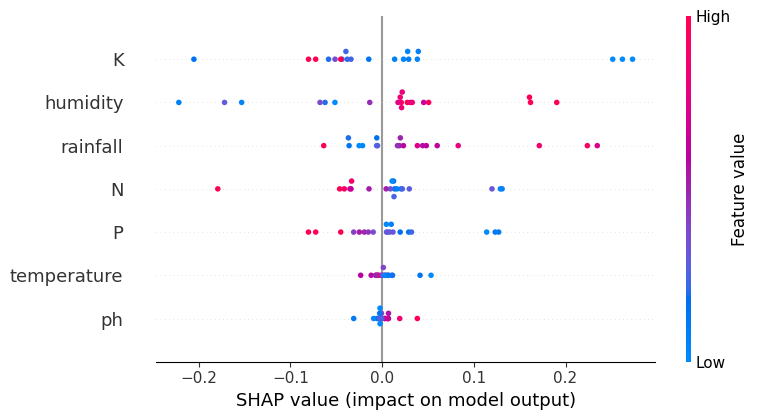

In [15]:
# %% [12] EXPLAINABILITY — SHAP
import shap

explainer_crop = shap.KernelExplainer(crop_model.predict, X_train[:100])
shap_values_crop = explainer_crop.shap_values(X_test[:20])

print("SHAP values shape:", np.array(shap_values_crop).shape)  # (20, 7, 22) typically

# Plot for one specific class — e.g. the most common predicted crop in this test batch
sample_preds = crop_model.predict(X_test[:20]).argmax(axis=1)
top_class_idx = np.bincount(sample_preds).argmax()
top_class_name = crop_encoder.inverse_transform([top_class_idx])[0]
print(f"Explaining class: {top_class_name} (class index {top_class_idx})")

shap.summary_plot(
    shap_values_crop[:, :, top_class_idx], X_test[:20], feature_names=NUM_COLS_CROP
)

In [16]:
# %% [13] INFERENCE PIPELINE — combine both stages
fert_known_crops = set(fert_crop_encoder.classes_)

def recommend(N, P, K, temperature, humidity, ph, rainfall, soil_type, moisture):
    x_crop = scaler_crop.transform([[N, P, K, temperature, humidity, ph, rainfall]])
    crop_probs = crop_model.predict(x_crop)[0]
    top_crop_id = crop_probs.argmax()
    top_crop = crop_encoder.inverse_transform([top_crop_id])[0]

    if top_crop not in fert_known_crops:
        return {
            "recommended_crop": top_crop,
            "crop_confidence": float(crop_probs.max()),
            "recommended_fertilizer": None,
            "fertilizer_confidence": None,
            "note": f"No fertilizer data available for '{top_crop}' — fertilizer dataset doesn't cover this crop.",
        }

    x_fert_num = scaler_fert.transform([[temperature, humidity, moisture, N, K, P]])
    soil_id = soil_encoder.transform([soil_type])
    fert_crop_id = fert_crop_encoder.transform([top_crop])
    fert_probs = fert_model.predict([x_fert_num, soil_id, fert_crop_id])[0]
    top_fert = fert_encoder.inverse_transform([fert_probs.argmax()])[0]

    return {
        "recommended_crop": top_crop,
        "crop_confidence": float(crop_probs.max()),
        "recommended_fertilizer": top_fert,
        "fertilizer_confidence": float(fert_probs.max()),
        "note": None,
    }

In [17]:
# %% [14] GRADIO APP
import gradio as gr

def gradio_predict(N, P, K, temperature, humidity, ph, rainfall, soil_type, moisture):
    result = recommend(N, P, K, temperature, humidity, ph, rainfall, soil_type, moisture)
    crop_text = f"{result['recommended_crop']} ({result['crop_confidence']:.1%} confidence)"
    if result["recommended_fertilizer"] is None:
        fert_text = result["note"]
    else:
        fert_text = f"{result['recommended_fertilizer']} ({result['fertilizer_confidence']:.1%} confidence)"
    return crop_text, fert_text

demo = gr.Interface(
    fn=gradio_predict,
    inputs=[
        gr.Number(label="Nitrogen (N)"),
        gr.Number(label="Phosphorous (P)"),
        gr.Number(label="Potassium (K)"),
        gr.Number(label="Temperature (°C)"),
        gr.Number(label="Humidity (%)"),
        gr.Number(label="pH"),
        gr.Number(label="Rainfall (mm)"),
        gr.Dropdown(choices=list(soil_encoder.classes_), label="Soil Type"),
        gr.Number(label="Moisture (%)"),
    ],
    outputs=[gr.Textbox(label="Recommended Crop"), gr.Textbox(label="Recommended Fertilizer")],
    title="M1 — Crop & Fertilizer Recommender",
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f85171a81ec518812.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [18]:
# does the model predict different classes for different inputs at all?
test_batch = X_num_scaled[:50]
preds = crop_model.predict(test_batch).argmax(axis=1)
print(np.bincount(preds))  # if one number dominates, model has collapsed
print(f"Training accuracy: {history_crop.history['accuracy'][-1]:.4f}")
print(f"Validation accuracy: {history_crop.history['val_accuracy'][-1]:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
[ 0  0  0  0  0  0  0  0  2  0  0  0  0  0  0  0  0  0  0  0 48]
Training accuracy: 0.9747
Validation accuracy: 0.9773


In [19]:
print(scaler_crop.mean_)  # should NOT be all zeros or all ones

[ 50.55181818  53.36272727  48.14909091  25.61624385  71.48177922
   6.46948007 103.46365542]


In [20]:
print('rice' in fert_crop_encoder.classes_)
print(sorted(fert_crop_encoder.classes_))

True
[np.str_('barley'), np.str_('cotton'), np.str_('groundnuts'), np.str_('maize'), np.str_('millets'), np.str_('oilseeds'), np.str_('pulses'), np.str_('rice'), np.str_('sugarcane'), np.str_('tobacco'), np.str_('wheat')]


In [21]:
idx = np.random.choice(len(X_num_scaled), 50, replace=False)
preds = crop_model.predict(X_num_scaled[idx]).argmax(axis=1)
print(np.bincount(preds))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[3 3 2 2 2 4 2 1 3 1 2 1 2 1 3 2 3 1 4 2 3 3]


In [23]:
# fix the confidence score for every crop
# fix the non-overlapping crop classes of datasets
# why have you chosen model parameters like these? explain your model architecture.
# show comparison and why the current model architecture one is better


In [ ]:
# %% [15] TASK 1 - calibrated recommender from saved artifacts (no retraining)
# Requires the repo (m1/, app.py, models/) next to this notebook; set REPO to its path.
# models/ is produced by: scripts/task1_calibration.py final --variant 'E_ensemble5+TS'
#                    and: scripts/train_stage2_notebook.py
import sys
REPO = '.'
sys.path.insert(0, REPO)
from m1.recommender import recommend
recommend(N=90, P=42, K=43, temperature=20.8, humidity=82, ph=6.5, rainfall=202,
          soil_type='Clayey', moisture=45)

In [ ]:
# %% [16] TASK 1 - Gradio app (top-3 calibrated crops, range guard, 'uncertain' flag)
from app import build_demo
build_demo().launch(share=True)